# HST Calibration Assignment  

In [1]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import os

### Loading Files and Creating Dictionary

In [2]:
cal_folder= "hst-calibration/"
processed_folder = "hst-processed/"

cal_set = {
    "ubai2505m": os.path.join(cal_folder, "ubai2505m"),
    "ubai2507m": os.path.join(cal_folder, "ubai2507m"),
    "ubai2508m": os.path.join(cal_folder, "ubai2508m"),
}

In [3]:
def load_calibration_files(cal_sets):

    result = {}

    for name, cal_path in cal_sets.items():
        fits_files = [f for f in os.listdir(cal_path) if f.endswith(".fits")]

        file_dict = {
            f.split("_")[-1].replace(".fits", "").upper(): os.path.join(cal_path, f)
            for f in fits_files
        }

        result[name] = file_dict

    return result

cal_file_dict = load_calibration_files(cal_set)


In [66]:
cal_file_dict 

{'ubai2505m': {'ATODFILE': 'hst-calibration/ubai2505m\\ubai2505m_atodfile.fits',
  'BIASFILE': 'hst-calibration/ubai2505m\\ubai2505m_biasfile.fits',
  'BLEVFILE': 'hst-calibration/ubai2505m\\ubai2505m_blevfile.fits',
  'DARKFILE': 'hst-calibration/ubai2505m\\ubai2505m_darkfile.fits',
  'FLATFILE': 'hst-calibration/ubai2505m\\ubai2505m_flatfile.fits',
  'MASKFILE': 'hst-calibration/ubai2505m\\ubai2505m_maskfile.fits',
  'RAW': 'hst-calibration/ubai2505m\\ubai2505m_raw.fits'},
 'ubai2507m': {'ATODFILE': 'hst-calibration/ubai2507m\\ubai2507m_atodfile.fits',
  'BIASFILE': 'hst-calibration/ubai2507m\\ubai2507m_biasfile.fits',
  'BLEVFILE': 'hst-calibration/ubai2507m\\ubai2507m_blevfile.fits',
  'DARKFILE': 'hst-calibration/ubai2507m\\ubai2507m_darkfile.fits',
  'FLATFILE': 'hst-calibration/ubai2507m\\ubai2507m_flatfile.fits',
  'MASKFILE': 'hst-calibration/ubai2507m\\ubai2507m_maskfile.fits',
  'RAW': 'hst-calibration/ubai2507m\\ubai2507m_raw.fits'},
 'ubai2508m': {'ATODFILE': 'hst-calibrat

In [75]:
# def load_fits(path):
#     with fits.open(path) as hdul:
#         return hdul[0].data.astype(float), hdul[0].header

def load_fits(path):
    with fits.open(path) as hdul:
        for hdu in hdul:
            if hdu.data is not None:
                return np.asarray(hdu.data, dtype=float), hdu.header
        raise ValueError(f"No image data found in {path}")

ubai2507_paths = cal_file_dict['ubai2507m']
raw, _ = load_fits(ubai2507_paths['RAW'])
bias, _ = load_fits(ubai2507_paths['BIASFILE'])
mask, _ = load_fits(ubai2507_paths['MASKFILE'])
blev, _ = load_fits(ubai2507_paths['BLEVFILE'])
flat, _ = load_fits(ubai2507_paths['FLATFILE'])
dark, _ = load_fits(ubai2507_paths['DARKFILE'])

### For Visualisation...

In [83]:
def show_image(img, title, size=(6,6)):
    plt.figure(figsize=size)
    plt.imshow(img, cmap="inferno", origin="lower")
    plt.title(title)
    plt.colorbar()
    plt.show()


# for viewing result
def percentile_normalise(image, pmax, pmin):

    res = np.asarray(image, dtype=np.float64)
    vmin, vmax = np.percentile(image, (pmin, pmax))
    norm = (res - vmin) / (vmax - vmin)

    return np.clip(norm, 0, 1)

### 1. Mask invalid data with MASKFILE

In [84]:
def apply_mask(raw_chip, mask_chip):
    masked = raw_chip.copy()
    masked[mask_chip != 0] = np.nan
    return masked

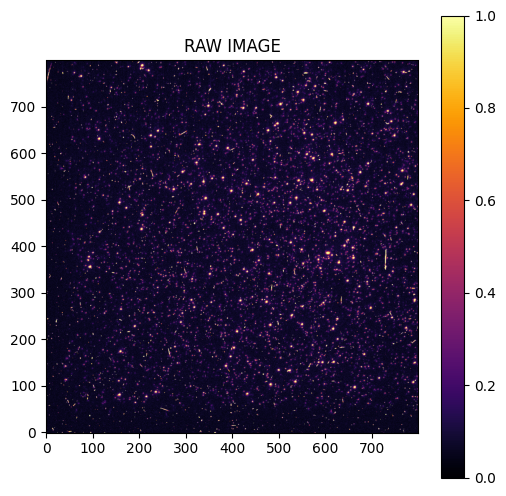

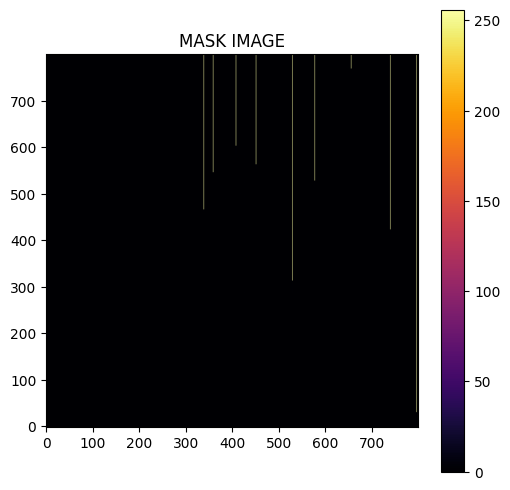

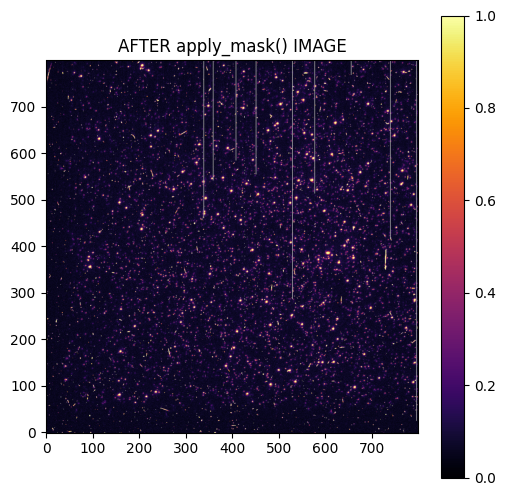

In [85]:
#adding normalisation to see result better
raw = percentile_normalise(raw, 99, 2)
masked = apply_mask(raw[0], mask[0])

show_image(raw[0], 'RAW IMAGE')
show_image(mask[0], 'MASK IMAGE')
show_image(masked, 'AFTER apply_mask() IMAGE')

### 3. Bias level with BLEVFILE

In [60]:
def parse_blev_file(filename, chip=0):
  with fits.open(filename) as hdul:
    data = hdul[chip].data

    # some code to parse odd and even columns here 
    odd_vals = your_odd_routine
    even_vals = your_even_routine

    return np.mean(odd_vals), np.mean(even_vals)

  #---------------------------------------------------------------------

  def apply_bias_corr(image, odd_mean, even_mean):
  # something here 


_IncompleteInputError: incomplete input (3686501724.py, line 14)

### 4. Remove bias image with BIASFILE

In [9]:
def subtract_bias(raw, bias):
    return raw - bias

### 5. Subtract dark with DARKFILE 

In [10]:
def subtract_dark(raw, dark, exptime):
    return raw - dark * exptime

### 6. Flatfield correction with FLATFILE

In [11]:
def apply_flat(raw, flat):
    return raw * flat